In [15]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [16]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [17]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
ZCT = 50
ZIM = 53

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.H_sys(PHI, 'li', XCT[i], YCT, ZCT, ZIM)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('linear_E_vs_xct_Zdiff_{}.npy'.format(ZIM-ZCT), Ep)

[-0.88805143 -0.88483183 -0.36081392 -0.35886782  0.35886782  0.36081392
  0.88483183  0.88805143]
[-0.88599376 -0.88279616 -0.36300297 -0.36107481  0.36107481  0.36300297
  0.88279616  0.88599376]
[-0.8830372  -0.87988098 -0.36646521 -0.36456781  0.36456781  0.36646521
  0.87988098  0.8830372 ]
[-0.87922982 -0.87614142 -0.37001335 -0.3681601   0.3681601   0.37001335
  0.87614142  0.87922982]
[-0.87436313 -0.87135875 -0.37043214 -0.36862504  0.36862504  0.37043214
  0.87135875  0.87436313]
[-0.8676662  -0.86474593 -0.36554438 -0.36377412  0.36377412  0.36554438
  0.86474593  0.8676662 ]
[-0.85884382 -0.85600139 -0.35579112 -0.35404671  0.35404671  0.35579112
  0.85600139  0.85884382]
[-0.84873242 -0.84595845 -0.34319592 -0.34146876  0.34146876  0.34319592
  0.84595845  0.84873242]
[-0.83908829 -0.83636899 -0.33056118 -0.32884499  0.32884499  0.33056118
  0.83636899  0.83908829]
[-0.83195109 -0.82926801 -0.32091886 -0.31920893  0.31920893  0.32091886
  0.82926801  0.83195109]
[-0.828943

In [8]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_Zdiff_2.npy")

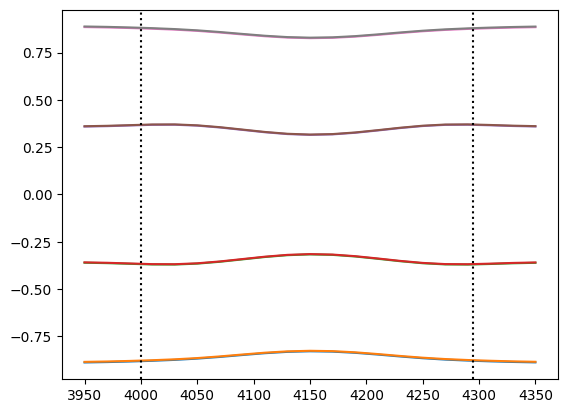

In [18]:
plt.plot(XCT, Ep[:, :])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

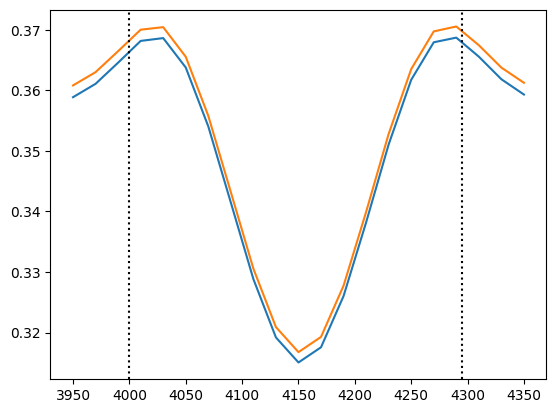

In [19]:
plt.plot(XCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

(0.0, 0.002335326988862496)

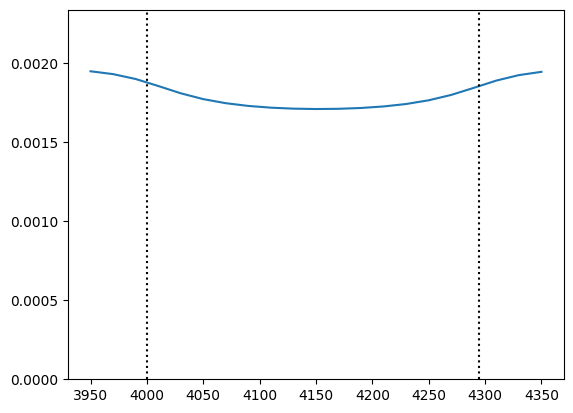

In [20]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.ylim(ymin=0)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

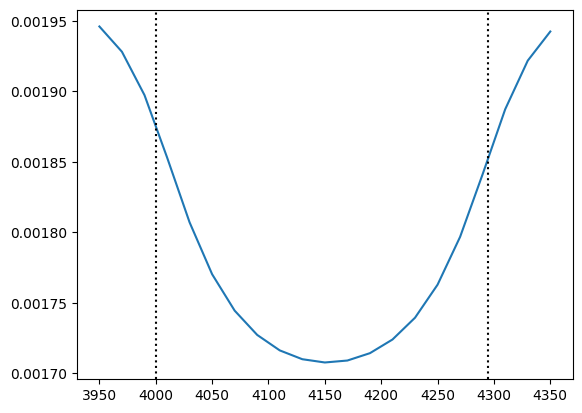

In [21]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [13]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\linear_E_vs_xct_V1.npy")

(0.0, 0.0023691305210776113)

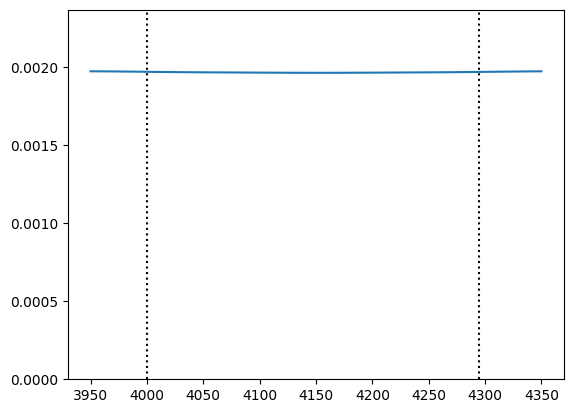

In [14]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))